Types of regression models

**Linear Regression** is the simplest form of regression model with no limit to the number of features used. Linear regression comes in many forms, often named by the number of features used and the shape of curve that fits. 

**Decision trees** take a step by step approach to predicting variable. If we think of our bicycle example, the decision tree might be first split examples between ones that are during spring/summer and autumn/winter, make a prediciton based on the day of the week. 

**Ensemble algorithm** construct not just one decision tree, but a large number of trees allowing better predicitons on more complex data. Ensemble algorithms such as Random forest, ae widely used in machine learning and data science due to their strong prediction abilities. 

Data scientists often experiment with using different models. 

In [15]:
# Experimenting with different regression models

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

bike_data = pd.read_csv('daily-bike-share.csv')
bike_data['day'] = pd.to_datetime(bike_data['dteday']).dt.day
bike_data.head()



,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,rentals,day
0,1,1/1/2011,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,1
1,2,1/2/2011,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,2
2,3,1/3/2011,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,3
3,4,1/4/2011,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,4
4,5,1/5/2011,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,5


In [16]:
numeric_features = ['temp', 'atemp', 'hum', 'windspeed']
categorical_features = ['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'day']

bike_data[numeric_features + ['rentals']].describe()

,temp,atemp,hum,windspeed,rentals
count,731.000000,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486,848.176471
std,0.183051,0.162961,0.142429,0.077498,686.622488
min,0.059130,0.079070,0.000000,0.022392,2.000000
25%,0.337083,0.337842,0.520000,0.134950,315.500000
50%,0.498333,0.486733,0.626667,0.180975,713.000000
75%,0.655417,0.608602,0.730209,0.233214,1096.000000
max,0.861667,0.840896,0.972500,0.507463,3410.000000


In [17]:
# Seperate features and label
X, y = bike_data[['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit','temp', 'atemp', 'hum', 'windspeed']].values, bike_data['rentals'].values


X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)


Lasso()
Mean Squared Error: 206671.84
Root Mean Squared Error: 454.61
R^2 Score: 0.61


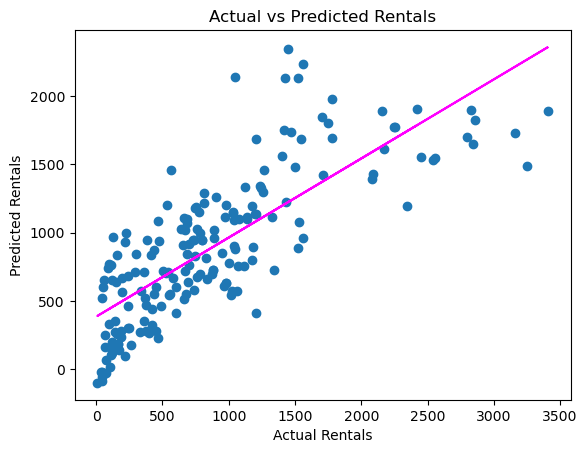

In [21]:
# Linear model : Lasso Regression
from sklearn.linear_model import Lasso
model = Lasso().fit(X_train, y_train)
print(model)

# Evaluate the Trained model
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2 = r2_score(y_test, predictions)
print(f'R^2 Score: {r2:.2f}')

# Plot predictions vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test,p(y_test),color='magenta')
plt.show()

In [23]:
# Decision tree algorithm
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import export_text

model = DecisionTreeRegressor().fit(X_train, y_train)
print(model)
tree = export_text(model)
print(tree)



DecisionTreeRegressor()
|--- feature_6 <= 0.45
|   |--- feature_4 <= 0.50
|   |   |--- feature_7 <= 0.32
|   |   |   |--- feature_8 <= 0.41
|   |   |   |   |--- feature_1 <= 2.50
|   |   |   |   |   |--- feature_3 <= 3.00
|   |   |   |   |   |   |--- feature_7 <= 0.27
|   |   |   |   |   |   |   |--- value: [515.00]
|   |   |   |   |   |   |--- feature_7 >  0.27
|   |   |   |   |   |   |   |--- value: [558.00]
|   |   |   |   |   |--- feature_3 >  3.00
|   |   |   |   |   |   |--- value: [317.00]
|   |   |   |   |--- feature_1 >  2.50
|   |   |   |   |   |--- feature_9 <= 0.28
|   |   |   |   |   |   |--- feature_0 <= 1.50
|   |   |   |   |   |   |   |--- value: [968.00]
|   |   |   |   |   |   |--- feature_0 >  1.50
|   |   |   |   |   |   |   |--- value: [981.00]
|   |   |   |   |   |--- feature_9 >  0.28
|   |   |   |   |   |   |--- feature_7 <= 0.28
|   |   |   |   |   |   |   |--- value: [532.00]
|   |   |   |   |   |   |--- feature_7 >  0.28
|   |   |   |   |   |   |   |--- value

Mean Squared Error: 273661.49
Root Mean Squared Error: 523.13
R^2 Score: 0.49


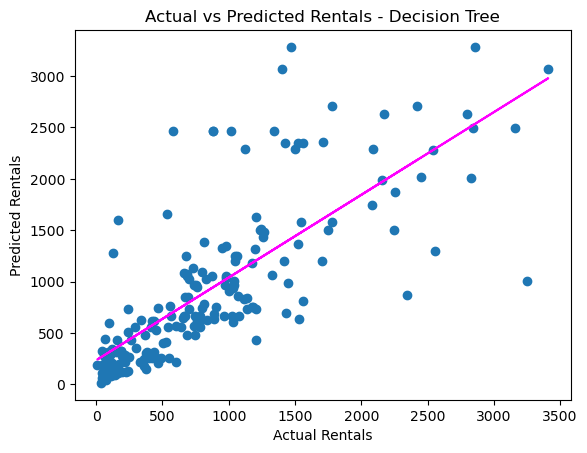

In [24]:
# evaluate the decision tree model
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2 = r2_score(y_test, predictions)
print(f'R^2 Score: {r2:.2f}')

# plot predicted vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals - Decision Tree')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test,p(y_test),color='magenta')
plt.show()



RandomForestRegressor()
Mean Squared Error: 118333.67
Root Mean Squared Error: 344.00
R^2 Score: 0.78


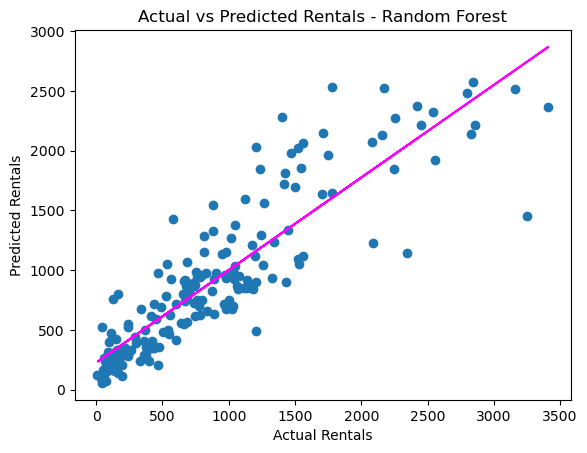

In [25]:
# Ensemble model : Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Train a model 
model = RandomForestRegressor().fit(X_train, y_train)
print(model)    

# Evaluate the trained model
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2 = r2_score(y_test, predictions)
print(f'R^2 Score: {r2:.2f}')

# Plot predicted vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals - Random Forest')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test,p(y_test),color='magenta')
plt.show()

GradientBoostingRegressor()
Mean Squared Error: 106134.81
Root Mean Squared Error: 325.78
R^2 Score: 0.80


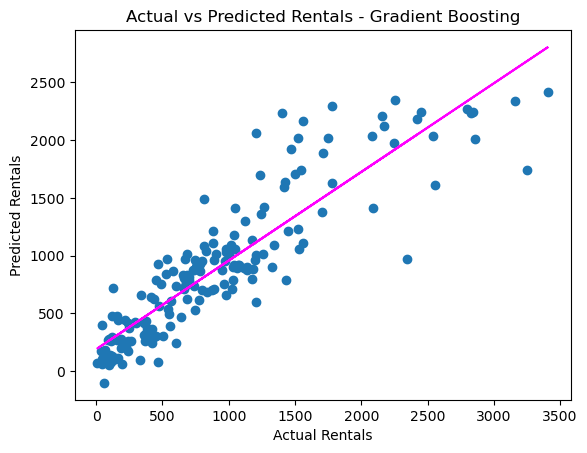

In [26]:
# Ensemble model : Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

# fit a lasso model on the training set
model = GradientBoostingRegressor().fit(X_train, y_train)
print(model)

# Evaluate the model using the test data
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2 = r2_score(y_test, predictions)
print(f'R^2 Score: {r2:.2f}')

# Plot predicted vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals - Gradient Boosting')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test,p(y_test),color='magenta')
plt.show()

